# B3 — DDR

B1 plus targeted grade 3 sampling to 10% with proportional non-grade-3 replacement tests whether more exposure improves grade 3 recognition.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

The historical runner and grade 3 sampler were external. The export records their hashes. [foundation adaptation](../../novelty/foundation_adaptation.py) is a component reference and exposes B0–B2 only.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B3', 'DDR'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = '8332a762a1b0c596dc768f187d97bccafc56bb32827ce0a3c738aa2f04d072b4'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B3 recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | ordinary CE |
| implementation_sha256 | 6adb1c65bd030c8924bc89e8f471833f0e574a518ba0dd2408170ee6b427be47 |
| manifest_sha256 | 7bc3e3916e012bc46fcd9cd69aa469e0daf3229e1273f1d8ecb6054899bf6eb1 |
| train / validation counts | {'train': 10018, 'val': 1252} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  },
  "sampling": {
    "augmentation": "B1 unchanged; seed/epoch/image_id",
    "protocol": "B3-grade3-targeted-sampling-v1",
    "replacement": "proportional non-grade3 removal",
    "sampler_sha256": "ff6e2a7f999446a6bcbbb78d25305a96dbd6499754530170d521575f93f2f767",
    "seed_rule": "seed + epoch",
    "target_fraction": 0.1,
    "target_grade": 3
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.808486 | 0.68866 | 0.484483 | 0.662009 | 0.686475 | 0.528449 |
| 2 | 0.602295 | 0.775105 | 0.601182 | 0.754668 | 0.811767 | 0.357656 |
| 3 | 0.517205 | 0.809543 | 0.646705 | 0.789953 | 0.84469 | 0.301358 |
| 4 | 0.452467 | 0.834997 | 0.685998 | 0.816726 | 0.861441 | 0.265023 |
| 5 | 0.394248 | 0.860351 | 0.716626 | 0.842684 | 0.885167 | 0.222599 |
| 6 | 0.346395 | 0.875424 | 0.746574 | 0.860722 | 0.898001 | 0.197944 |
| 7 | 0.313721 | 0.889998 | 0.771667 | 0.877464 | 0.91178 | 0.172889 |
| 8 | 0.27774 | 0.902076 | 0.798159 | 0.89192 | 0.924637 | 0.150529 |
| 9 | 0.23538 | 0.917149 | 0.826324 | 0.909091 | 0.937733 | 0.125374 |
| 10 | 0.214407 | 0.923937 | 0.84766 | 0.918646 | 0.944606 | 0.113096 |
| 11 | 0.181461 | 0.936015 | 0.872498 | 0.931645 | 0.956163 | 0.0928329 |
| 12 | 0.152326 | 0.947495 | 0.896194 | 0.94508 | 0.964736 | 0.0750649 |
| 13 | 0.13459 | 0.953683 | 0.909847 | 0.951539 | 0.969125 | 0.0658814 |
| 14 | 0.112895 | 0.961569 | 0.926592 | 0.960299 | 0.975159 | 0.0540028 |
| 15 | 0.0954157 | 0.969255 | 0.942893 | 0.968635 | 0.97961 | 0.0435217 |
| 16 | 0.0783779 | 0.974546 | 0.9542 | 0.973973 | 0.982455 | 0.0369335 |
| 17 | 0.0699488 | 0.976243 | 0.956452 | 0.975793 | 0.984721 | 0.03334 |
| 18 | 0.0515189 | 0.984628 | 0.972583 | 0.984389 | 0.990211 | 0.0214614 |
| 19 | 0.042039 | 0.987223 | 0.977592 | 0.987096 | 0.991751 | 0.0179677 |
| 20 | 0.0356165 | 0.98872 | 0.982468 | 0.988655 | 0.991745 | 0.0169695 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.666997 | 0.764377 | 0.507145 | 0.739266 | 0.757698 | 0.392971 |
| 2 | 0.609029 | 0.776358 | 0.552409 | 0.755125 | 0.781054 | 0.375399 |
| 3 | 0.595562 | 0.777157 | 0.562647 | 0.758914 | 0.782961 | 0.376198 |
| 4 | 0.581738 | 0.795527 | 0.579099 | 0.77273 | 0.800358 | 0.345048 |
| 5 | 0.580723 | 0.797923 | 0.593018 | 0.779787 | 0.803506 | 0.337061 |
| 6 | 0.593462 | 0.802716 | 0.59542 | 0.788617 | 0.810522 | 0.323482 |
| 7 | 0.584956 | 0.817891 | 0.598139 | 0.796482 | 0.819634 | 0.301118 |
| 8 | 0.584184 | 0.822684 | 0.626189 | 0.807628 | 0.832851 | 0.28754 |
| 9 | 0.595534 | 0.813898 | 0.62389 | 0.801881 | 0.822096 | 0.301917 |
| 10 | 0.64108 | 0.81869 | 0.58803 | 0.797486 | 0.832012 | 0.292332 |
| 11 | 0.639663 | 0.81869 | 0.651006 | 0.813732 | 0.843194 | 0.281949 |
| 12 | 0.694006 | 0.817093 | 0.629002 | 0.807575 | 0.827868 | 0.295527 |
| 13 | 0.739801 | 0.820288 | 0.632232 | 0.806569 | 0.832293 | 0.289137 |
| 14 | 0.742259 | 0.823482 | 0.633531 | 0.814375 | 0.843288 | 0.277955 |
| 15 | 0.800736 | 0.811502 | 0.623175 | 0.803224 | 0.822235 | 0.302716 |
| 16 | 0.835302 | 0.8123 | 0.645505 | 0.808562 | 0.833537 | 0.291534 |
| 17 | 0.888312 | 0.820288 | 0.630663 | 0.81184 | 0.841662 | 0.278754 |
| 18 | 1.04275 | 0.802716 | 0.608384 | 0.791845 | 0.829578 | 0.309105 |
| 19 | 1.04028 | 0.811502 | 0.630767 | 0.805308 | 0.839963 | 0.290735 |
| 20 | 1.12443 | 0.801118 | 0.629043 | 0.796137 | 0.825055 | 0.313898 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 1351.53 | 64.6841 | 1308.1 | 62.8528 | 7.41235 | 19.3556 | 2686451712 | 4002508800 | 204 | 91 | 20 |
| 2 | 1350 | 65.1232 | 1306.24 | 63.3694 | 7.42073 | 19.2251 | 2688548864 | 4190773248 | 165 | 115 | 28 |
| 3 | 1361.19 | 62.8063 | 1317.46 | 61.0591 | 7.35976 | 19.9343 | 2688548864 | 4190773248 | 125 | 154 | 25 |
| 4 | 1353.76 | 64.0965 | 1309.35 | 62.416 | 7.40011 | 19.533 | 2688548864 | 4307668992 | 159 | 97 | 55 |
| 5 | 1334.28 | 64.8603 | 1290 | 63.0461 | 7.50819 | 19.303 | 2688548864 | 4307668992 | 121 | 132 | 48 |
| 6 | 1172.29 | 57.3018 | 1130.85 | 55.6295 | 8.54569 | 21.8492 | 2688548864 | 4307668992 | 105 | 142 | 46 |
| 7 | 1107.55 | 56.4916 | 1066.49 | 54.8232 | 9.04515 | 22.1626 | 2688548864 | 4320313344 | 154 | 74 | 72 |
| 8 | 1129.17 | 55.0707 | 1088.06 | 53.4029 | 8.87204 | 22.7344 | 2688548864 | 4320313344 | 108 | 114 | 64 |
| 9 | 1124.83 | 54.9136 | 1083.74 | 53.2473 | 8.90623 | 22.7995 | 2688548864 | 4320313344 | 142 | 91 | 68 |
| 10 | 1114.83 | 55.3032 | 1073.73 | 53.6368 | 8.98615 | 22.6389 | 2688548864 | 4353167360 | 130 | 97 | 93 |
| 11 | 1133.99 | 54.8005 | 1092.88 | 53.1348 | 8.83427 | 22.8465 | 2688548864 | 4353167360 | 124 | 103 | 71 |
| 12 | 1120.57 | 56.9328 | 1079.46 | 55.2615 | 8.94009 | 21.9909 | 2688548864 | 4415094784 | 110 | 119 | 89 |
| 13 | 1124.73 | 55.4397 | 1083.62 | 53.7732 | 8.90705 | 22.5831 | 2688548864 | 4473585664 | 146 | 79 | 107 |
| 14 | 1105.21 | 53.4954 | 1064.2 | 51.8235 | 9.06437 | 23.4039 | 2688548864 | 4473585664 | 119 | 102 | 103 |
| 15 | 1132.41 | 70.5736 | 1082.66 | 67.7478 | 8.84662 | 17.7404 | 2688548864 | 4473585664 | 118 | 118 | 108 |
| 16 | 1384.63 | 53.2073 | 1307.7 | 51.5355 | 7.23517 | 23.5306 | 2688548864 | 4473585664 | 133 | 102 | 108 |
| 17 | 1044.36 | 53.6992 | 1003.58 | 52.0162 | 9.59246 | 23.315 | 2688548864 | 4473585664 | 137 | 88 | 120 |
| 18 | 1049.85 | 53.6522 | 1009.06 | 51.9839 | 9.54228 | 23.3355 | 2688548864 | 4473585664 | 161 | 86 | 131 |
| 19 | 1070.09 | 52.8775 | 1029.29 | 51.2001 | 9.36181 | 23.6774 | 2688548864 | 4473585664 | 134 | 102 | 140 |
| 20 | 1056.1 | 56.329 | 1015.24 | 54.6618 | 9.48583 | 22.2266 | 2688548864 | 4473585664 | 113 | 136 | 154 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 5 | True |
| 6 | 1e-05 | 0.001 | — | 6 | True |
| 7 | 1e-05 | 0.001 | — | 7 | True |
| 8 | 1e-05 | 0.001 | — | 8 | True |
| 9 | 1e-05 | 0.001 | — | 8 | False |
| 10 | 1e-05 | 0.001 | — | 8 | False |
| 11 | 1e-05 | 0.001 | — | 11 | True |
| 12 | 1e-05 | 0.001 | — | 11 | False |
| 13 | 1e-05 | 0.001 | — | 11 | False |
| 14 | 1e-05 | 0.001 | — | 11 | False |
| 15 | 1e-05 | 0.001 | — | 11 | False |
| 16 | 1e-05 | 0.001 | — | 11 | False |
| 17 | 1e-05 | 0.001 | — | 11 | False |
| 18 | 1e-05 | 0.001 | — | 11 | False |
| 19 | 1e-05 | 0.001 | — | 11 | False |
| 20 | 1e-05 | 0.001 | — | 11 | False |

## B3 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 11 | 0.81869 | 0.651006 | 0.813732 | 0.843194 | 0.281949 | 1025 | 227 | 124 | 103 |

Frozen validation only. The selected checkpoint SHA-256 is `8332a762a1b0c596dc768f187d97bccafc56bb32827ce0a3c738aa2f04d072b4`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 579 | 14 | 32 | 0 | 1 |
| 1 | 20 | 13 | 30 | 0 | 0 |
| 2 | 56 | 21 | 347 | 9 | 15 |
| 3 | 0 | 0 | 10 | 12 | 2 |
| 4 | 2 | 0 | 14 | 1 | 74 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 92.492 | 2.23642 | 5.11182 | 0 | 0.159744 |
| 1 | 31.746 | 20.6349 | 47.619 | 0 | 0 |
| 2 | 12.5 | 4.6875 | 77.4554 | 2.00893 | 3.34821 |
| 3 | 0 | 0 | 41.6667 | 50 | 8.33333 |
| 4 | 2.1978 | 0 | 15.3846 | 1.0989 | 81.3187 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.881279 | 0.92492 | 0.902572 | 626 | 579 |
| 1 | 0.270833 | 0.206349 | 0.234234 | 63 | 13 |
| 2 | 0.801386 | 0.774554 | 0.787741 | 448 | 347 |
| 3 | 0.545455 | 0.5 | 0.521739 | 24 | 12 |
| 4 | 0.804348 | 0.813187 | 0.808743 | 91 | 74 |

Minority-grade predictions on the diagonal were grade 1 13/63, grade 3 12/24. The largest off-diagonal counts were 2 → 0 (56), 0 → 2 (32), 1 → 2 (30). The matrix gives 107 adjacent errors and 120 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/DDR_B3_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/DDR_B3_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

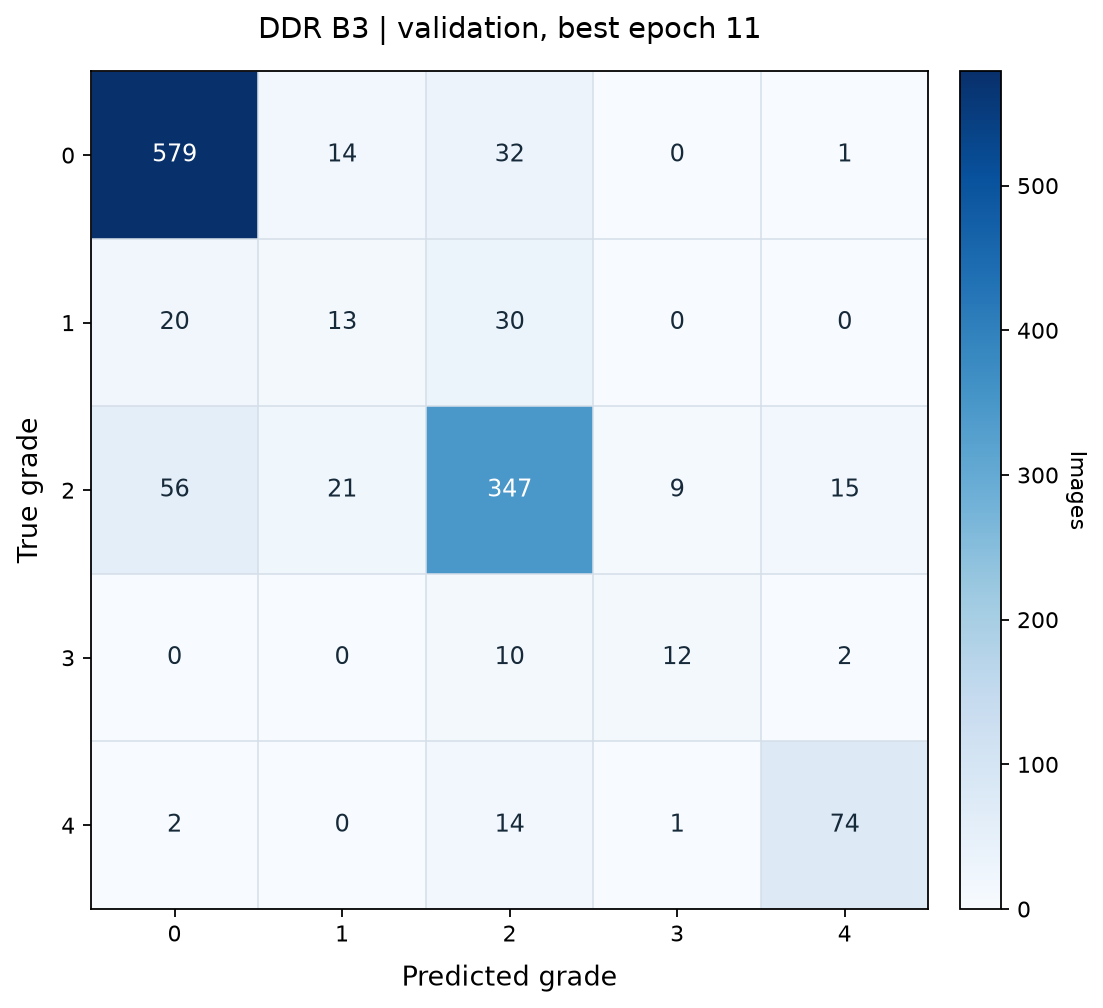

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/DDR_B3_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

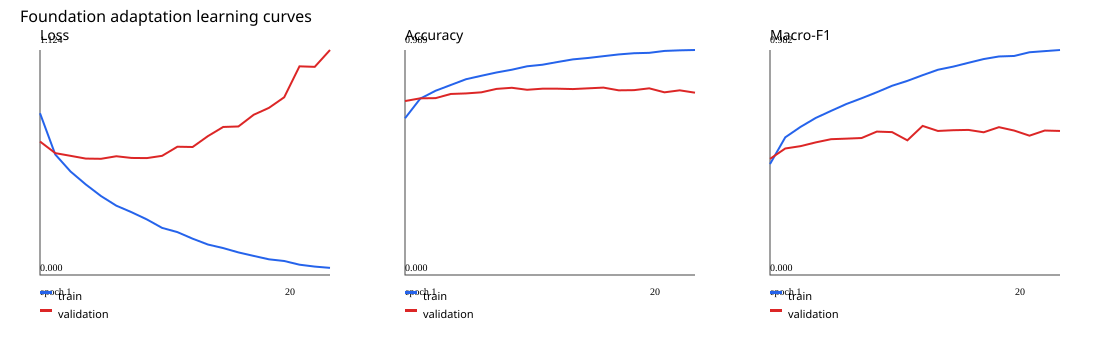

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/DDR_B3_learning_curves.svg')))

## Interpretation and limits

Compared with B1 on this validation split, macro-F1 changed by -0.001140, grade 1 recall by +0.0317, and grade 3 recall by +0.0833.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Execution availability

The original external orchestration and input selection are prerequisites for a historical rerun. The signed-off reporting path reads aggregate evidence only. There is no substitute training cell for these arms.